<a href="https://colab.research.google.com/github/Valeria1100/Confiabilidad-y-planeaci-n-de-capacidad-de-un-servicio-de-inferencia-de-IA./blob/main/EjerciciosD_y_E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Fonseca Puntos D Y E

#D

D1

In [382]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2 as chi2_dist

In [383]:
t1 = 100
t2 = 450

In [384]:
datos_D1 = solicitudes[["tam_kb", "cache_hit"]].copy()

# Eliminar registros con datos faltantes
datos_D1 = datos_D1.dropna()

# Conservar tamaños positivos y valores válidos de caché
datos_D1 = datos_D1[(datos_D1["tam_kb"] > 0) &(datos_D1["cache_hit"].isin([0, 1]))].copy()
print("Cantidad de registros analizados:", len(datos_D1))

Cantidad de registros analizados: 18512


In [385]:
datos_D1["clase_tamano"] = pd.cut(
    datos_D1["tam_kb"],
    bins=[0, t1, t2, np.inf],
    labels=[
        "Clase 1 (≤100 KB)",
        "Clase 2 (100-450 KB)",
        "Clase 3 (>450 KB)"
    ],
    include_lowest=True
)

display(datos_D1.head(10))

,tam_kb,cache_hit,clase_tamano
0,114.370000,0,Clase 2 (100-450 KB)
1,140.450000,0,Clase 2 (100-450 KB)
2,84.030000,1,Clase 1 (≤100 KB)
3,162.240000,0,Clase 2 (100-450 KB)
4,312.010000,0,Clase 2 (100-450 KB)
5,219.810000,0,Clase 2 (100-450 KB)
6,224.200000,0,Clase 2 (100-450 KB)
7,244.820000,1,Clase 2 (100-450 KB)
8,312.140000,0,Clase 2 (100-450 KB)
9,256.100000,0,Clase 2 (100-450 KB)


In [386]:
frecuencias = pd.crosstab(datos_D1["clase_tamano"],datos_D1["cache_hit"])
frecuencias = frecuencias.reindex(columns=[0, 1],fill_value=0)
frecuencias.columns = ["Sin caché (0)", "Con caché (1)"]

display(frecuencias)

,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),2386,3029
Clase 2 (100-450 KB),8509,3243
Clase 3 (>450 KB),1219,126


In [387]:
distribucion_conjunta = frecuencias / frecuencias.values.sum()

display(distribucion_conjunta)

,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),0.128889,0.163624
Clase 2 (100-450 KB),0.459648,0.175184
Clase 3 (>450 KB),0.065849,0.006806


In [388]:
marginal_clase = distribucion_conjunta.sum(axis=1)
marginal_cache = distribucion_conjunta.sum(axis=0)

print("Marginal de clase de tamaño:")
display(marginal_clase)

print("Marginal de cache_hit:")
display(marginal_cache)

Marginal de clase de tamaño:


,0
clase_tamano,
Clase 1 (≤100 KB),0.292513
Clase 2 (100-450 KB),0.634831
Clase 3 (>450 KB),0.072656


Marginal de cache_hit:


,0
Sin caché (0),0.654386
Con caché (1),0.345614


In [389]:
condicional_cache = distribucion_conjunta.div(marginal_clase,axis=0)

print("Distribución de cache_hit condicionada a la clase:")
display(condicional_cache)

Distribución de cache_hit condicionada a la clase:


,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),0.440628,0.559372
Clase 2 (100-450 KB),0.724047,0.275953
Clase 3 (>450 KB),0.906320,0.093680


In [390]:
condicional_clase = distribucion_conjunta.div(marginal_cache,axis=1)

print("Distribución de clases condicionada a cache_hit:")
display(condicional_clase)

Distribución de clases condicionada a cache_hit:


,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),0.196962,0.473429
Clase 2 (100-450 KB),0.702410,0.506877
Clase 3 (>450 KB),0.100627,0.019694


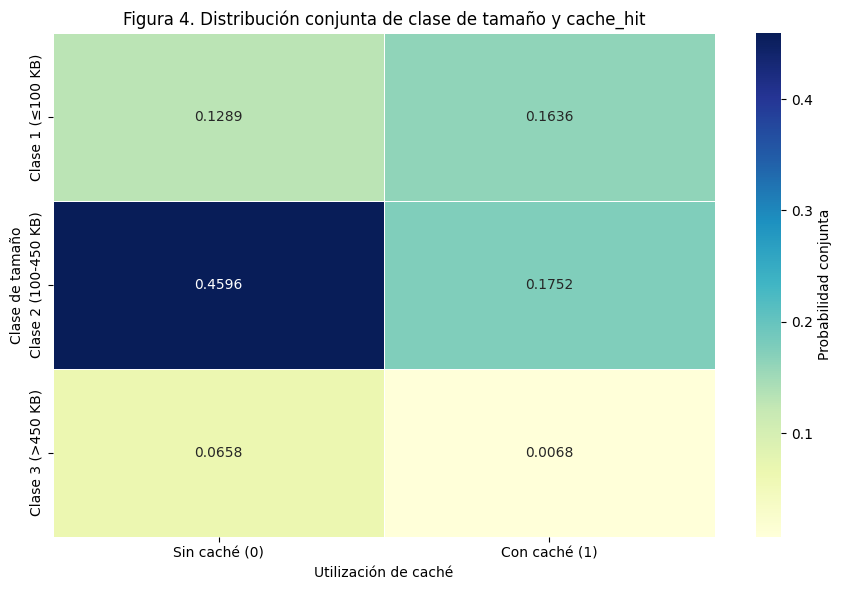

In [391]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    distribucion_conjunta,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Probabilidad conjunta"}
)

plt.title("Figura 4. Distribución conjunta de clase de tamaño y cache_hit")
plt.xlabel("Utilización de caché")
plt.ylabel("Clase de tamaño")

plt.tight_layout()
plt.show()

In [392]:
conjunta_independencia = pd.DataFrame(
    np.outer(
        marginal_clase.values,
        marginal_cache.values
    ),
    index=distribucion_conjunta.index,
    columns=distribucion_conjunta.columns
)

print("Distribución conjunta observada:")
display(distribucion_conjunta)

print("Distribución esperada bajo independencia:")
display(conjunta_independencia)

Distribución conjunta observada:


,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),0.128889,0.163624
Clase 2 (100-450 KB),0.459648,0.175184
Clase 3 (>450 KB),0.065849,0.006806


Distribución esperada bajo independencia:


,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),0.191416,0.101096
Clase 2 (100-450 KB),0.415425,0.219406
Clase 3 (>450 KB),0.047545,0.025111


In [393]:
diferencias = (distribucion_conjunta - conjunta_independencia)

print("Diferencias entre ambas distribuciones:")
display(diferencias)

print("Máxima diferencia absoluta:",diferencias.abs().to_numpy().max())

Diferencias entre ambas distribuciones:


,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),-0.062527,0.062527
Clase 2 (100-450 KB),0.044223,-0.044223
Clase 3 (>450 KB),0.018304,-0.018304


Máxima diferencia absoluta: 0.06252712039339664


In [394]:
from scipy.stats import chi2_contingency
chi2, p_valor, grados_libertad, esperados = chi2_contingency(frecuencias)

print("Estadístico chi-cuadrado:", chi2)
print("Grados de libertad:", grados_libertad)
print("Valor p:", p_valor)
print("Frecuencias esperadas:")
display(pd.DataFrame(esperados,index=frecuencias.index,columns=frecuencias.columns))

Estadístico chi-cuadrado: 1723.6159526016313
Grados de libertad: 2
Valor p: 0.0
Frecuencias esperadas:


,Sin caché (0),Con caché (1)
clase_tamano,,
Clase 1 (≤100 KB),"3,543.502053","1,871.497947"
Clase 2 (100-450 KB),"7,690.348315","4,061.651685"
Clase 3 (>450 KB),880.149633,464.850367


In [395]:
if p_valor < 0.01:
    print("Se rechaza H0: existe evidencia de asociación.")
else:
    print("No se rechaza H0: no hay evidencia suficiente de asociación.")

Se rechaza H0: existe evidencia de asociación.


In [396]:
from scipy.stats import norm

def intervalo_wilson(exitos, total, confianza=0.99):
    z = norm.ppf(1 - (1 - confianza) / 2)

    p = exitos / total

    denominador = 1 + z**2 / total

    centro = (
        p + z**2 / (2 * total)
    ) / denominador

    margen = (
        z * np.sqrt(
            p * (1 - p) / total +
            z**2 / (4 * total**2)
        )
    ) / denominador

    return centro - margen, centro + margen

In [397]:
resultados_intervalos = []

for clase in frecuencias.index:

    total = frecuencias.loc[clase].sum()
    exitos = frecuencias.loc[clase, "Con caché (1)"]

    proporcion = exitos / total

    inferior, superior = intervalo_wilson(
        exitos,
        total,
        confianza=0.99
    )

    resultados_intervalos.append({
        "Clase": clase,
        "Total": total,
        "Con caché": exitos,
        "Probabilidad": proporcion,
        "Límite inferior 99%": inferior,
        "Límite superior 99%": superior
    })

tabla_intervalos = pd.DataFrame(resultados_intervalos)

display(tabla_intervalos)

,Clase,Total,Con caché,Probabilidad,Límite inferior 99%,Límite superior 99%
0,Clase 1 (≤100 KB),5415,3029,0.559372,0.541932,0.576667
1,Clase 2 (100-450 KB),11752,3243,0.275953,0.265461,0.286698
2,Clase 3 (>450 KB),1345,126,0.093680,0.075163,0.116187


D2

In [398]:
datos_D2 = solicitudes[["tam_kb", "cache_hit", "gpu_ms"]].copy()

# Conservar registros válidos
datos_D2 = datos_D2.dropna()

datos_D2 = datos_D2[
    (datos_D2["tam_kb"] > 0) &
    (datos_D2["gpu_ms"] > 0) &
    (datos_D2["cache_hit"].isin([0, 1]))
].copy()

print("Registros válidos sin caché:", len(datos_D2))

Registros válidos sin caché: 12092


In [399]:
datos_D2["clase_tamano"] = pd.cut(
    datos_D2["tam_kb"],
    bins=[0, t1, t2, np.inf],
    labels=[
        "Clase 1 (≤100 KB)",
        "Clase 2 (100-450 KB)",
        "Clase 3 (>450 KB)"
    ],
    include_lowest=True
)

display(datos_D2[["tam_kb", "clase_tamano"]].head())

,tam_kb,clase_tamano
1,140.450000,Clase 2 (100-450 KB)
3,162.240000,Clase 2 (100-450 KB)
4,312.010000,Clase 2 (100-450 KB)
5,219.810000,Clase 2 (100-450 KB)
6,224.200000,Clase 2 (100-450 KB)


In [400]:
esperanza_clase = datos_D2.groupby(
    "clase_tamano",
    observed=True
)["gpu_ms"].agg(
    ["count", "mean", "std", "var"]
)

esperanza_clase.columns = [
    "Cantidad",
    "Esperanza",
    "Desviacion",
    "Varianza"
]

display(esperanza_clase)

,Cantidad,Esperanza,Desviacion,Varianza
clase_tamano,,,,
Clase 1 (≤100 KB),2386,37.629028,16.832452,283.331457
Clase 2 (100-450 KB),8489,71.490727,37.840213,"1,431.881707"
Clase 3 (>450 KB),1217,174.562892,97.140429,"9,436.262963"


In [401]:
datos_D2["intervalo_tamano"] = pd.qcut(
    datos_D2["tam_kb"],
    q=30,
    duplicates="drop"
)

estimacion_tamano = datos_D2.groupby(
    "intervalo_tamano",
    observed=True
).agg(
    tamano_promedio=("tam_kb", "median"),
    esperanza_gpu=("gpu_ms", "mean"),
    cantidad=("gpu_ms", "count")
).reset_index()

display(estimacion_tamano)

,intervalo_tamano,tamano_promedio,esperanza_gpu,cantidad
0,"(7.5089999999999995, 44.091]",34.150000,29.540347,404
1,"(44.091, 57.412]",51.240000,33.759132,403
2,"(57.412, 68.885]",63.350000,38.073400,403
3,"(68.885, 79.677]",74.530000,39.919107,403
4,"(79.677, 89.68]",84.860000,41.384208,404
5,"(89.68, 100.426]",95.010000,44.342886,402
6,"(100.426, 106.805]",103.410000,45.553921,403
7,"(106.805, 113.513]",110.190000,46.789206,403
8,"(113.513, 121.321]",117.070000,48.521762,403
9,"(121.321, 127.423]",124.140000,51.763995,403


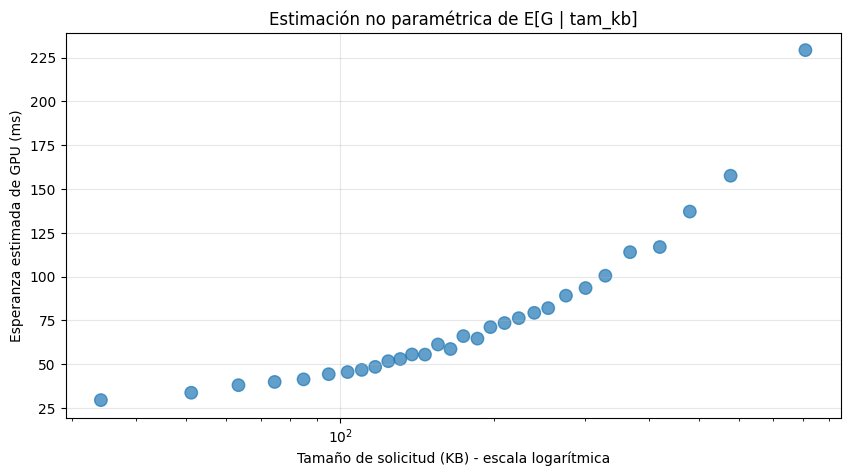

In [402]:
plt.figure(figsize=(10, 5))

plt.scatter(
    estimacion_tamano["tamano_promedio"],
    estimacion_tamano["esperanza_gpu"],
    s=estimacion_tamano["cantidad"] / 5,
    alpha=0.7
)

plt.xscale("log")

plt.xlabel("Tamaño de solicitud (KB) - escala logarítmica")
plt.ylabel("Esperanza estimada de GPU (ms)")
plt.title("Estimación no paramétrica de E[G | tam_kb]")
plt.grid(alpha=0.3)

plt.show()

In [403]:
media_global = datos_D2["gpu_ms"].mean()

probabilidades = (
    datos_D2["clase_tamano"]
    .value_counts(normalize=True)
    .sort_index()
)

esperanza_por_clase = (
    datos_D2.groupby("clase_tamano", observed=True)["gpu_ms"]
    .mean()
)

esperanza_total = (
    probabilidades * esperanza_por_clase
).sum()

print("Esperanza global:", media_global)
print("Esperanza calculada por clases:", esperanza_total)
print("Diferencia:", abs(media_global - esperanza_total))

Esperanza global: 75.18282170029772
Esperanza calculada por clases: 75.18282170029772
Diferencia: 0.0


In [404]:
varianza_global = datos_D2["gpu_ms"].var(ddof=0)

estadisticas = datos_D2.groupby(
    "clase_tamano",
    observed=True
)["gpu_ms"].agg(
    ["mean", "var", "count"]
)

estadisticas["var"] = datos_D2.groupby(
    "clase_tamano",
    observed=True
)["gpu_ms"].var(ddof=0)

probabilidades = estadisticas["count"] / estadisticas["count"].sum()
varianza_dentro = (probabilidades * estadisticas["var"]).sum()
varianza_entre = (probabilidades *(estadisticas["mean"] - media_global) ** 2).sum()
varianza_calculada = varianza_dentro + varianza_entre

print("Varianza global:", varianza_global)
print("Varianza dentro de las clases:", varianza_dentro)
print("Varianza entre las clases:", varianza_entre)
print("Suma de componentes:", varianza_calculada)
print("Diferencia:", abs(varianza_global - varianza_calculada))

Varianza global: 3291.7874891600845
Varianza dentro de las clases: 2009.9283173154627
Varianza entre las clases: 1281.8591718446087
Suma de componentes: 3291.7874891600713
Diferencia: 1.318767317570746e-11


In [405]:
fraccion_explicada = (varianza_entre / varianza_global) * 100

print("Fracción de Var(G) explicada por la clase:",round(fraccion_explicada, 2),"%")

Fracción de Var(G) explicada por la clase: 38.94 %


D3

In [406]:
datos = pd.read_csv("/content/solicitudes.csv")

print("Dataset cargado correctamente")
print("Dimensiones:", datos.shape)

display(datos.head())

Dataset cargado correctamente
Dimensiones: (18518, 10)


,id_solicitud,t_llegada_s,tam_kb,cache_hit,version,red_ms,gpu_ms,latencia_ms,intentos,exito
0,1,0.027000,114.370000,0,B,42.640000,-76.350000,118.990000,1,1
1,2,0.130000,140.450000,0,B,57.960000,53.520000,111.480000,1,1
2,3,0.291000,84.030000,1,B,12.110000,0.000000,12.110000,1,1
3,4,0.436000,162.240000,0,B,28.690000,61.080000,89.770000,1,1
4,5,0.569000,312.010000,0,B,27.560000,47.310000,74.870000,1,1


In [407]:
# Creamos una copia del dataset original
datos_D3 = datos.copy()

# Seleccionamos las solicitudes sin caché
datos_D3 = datos_D3[
    (datos_D3["cache_hit"] == 0) &
    (datos_D3["tam_kb"] > 0) &
    (datos_D3["gpu_ms"] > 0)
].copy()

# Eliminamos los registros que tengan datos faltantes
datos_D3 = datos_D3.dropna(
    subset=["tam_kb", "gpu_ms"]
)

# Eliminamos los valores infinitos
datos_D3 = datos_D3[
    np.isfinite(datos_D3["tam_kb"]) &
    np.isfinite(datos_D3["gpu_ms"])
].copy()

# Mostramos la cantidad de observaciones utilizadas
print("Observaciones utilizadas:", len(datos_D3))

# Mostramos los primeros registros filtrados
display(datos_D3.head())

Observaciones utilizadas: 12080


,id_solicitud,t_llegada_s,tam_kb,cache_hit,version,red_ms,gpu_ms,latencia_ms,intentos,exito
1,2,0.130000,140.450000,0,B,57.960000,53.520000,111.480000,1,1
3,4,0.436000,162.240000,0,B,28.690000,61.080000,89.770000,1,1
4,5,0.569000,312.010000,0,B,27.560000,47.310000,74.870000,1,1
5,6,0.749000,219.810000,0,A,35.010000,39.980000,74.980000,1,1
6,7,0.781000,224.200000,0,B,35.820000,60.100000,95.920000,1,1


In [408]:
# Guardamos el tamaño de cada solicitud en X
X = datos_D3["tam_kb"].to_numpy(dtype=float)

# Guardamos el tiempo de GPU en G
G = datos_D3["gpu_ms"].to_numpy(dtype=float)

# Calculamos la cantidad de observaciones
n = len(X)

# Calculamos la sumatoria de X
suma_X = np.sum(X)

# Calculamos la sumatoria de G
suma_G = np.sum(G)

# Calculamos la sumatoria de X al cuadrado
suma_X2 = np.sum(X**2)

# Calculamos la sumatoria del producto X por G
suma_XG = np.sum(X * G)

print("n =", n)
print("Sumatoria X =", suma_X)
print("Sumatoria G =", suma_G)
print("Sumatoria X² =", suma_X2)
print("Sumatoria XG =", suma_XG)

# Calculamos los promedios
promedio_X = np.mean(X)
promedio_G = np.mean(G)

print("\nPROMEDIOS")
print("Promedio X =", promedio_X)
print("Promedio G =", promedio_G)

n = 12080
Sumatoria X = 3701133.37
Sumatoria G = 908351.9299999999
Sumatoria X² = 905128230643.4061
Sumatoria XG = 351000271.9416

PROMEDIOS
Promedio X = 306.3852127483444
Promedio G = 75.19469619205297


In [409]:
# Centramos X restándole su promedio
Z = X - promedio_X

# Construimos la matriz de diseño
matriz_X = np.column_stack([
    np.ones(n),
    Z
])

# Calculamos la matriz X transpuesta por X
A = matriz_X.T @ matriz_X
# Calculamos el vector X transpuesta por G
b = matriz_X.T @ G
# Resolvemos el sistema matricial
coeficientes = np.linalg.solve(A, b)
# Obtenemos el intercepto centrado
alpha_0 = coeficientes[0]
# Obtenemos la pendiente
beta_1 = coeficientes[1]
# Recuperamos el intercepto original
beta_0 = alpha_0 - beta_1 * promedio_X

# Mostramos las matrices
print("MATRIZ A:")
print(A)
print("\nVECTOR b:")
print(b)
print("\nCOEFICIENTES")
print("Intercepto =", beta_0)
print("Pendiente =", beta_1)

# Mostramos la ecuación final
print("\nMODELO LINEAL:")
print(f"G estimado = {beta_0:.6f} + ({beta_1:.6f})X")

MATRIZ A:
[[ 1.20800000e+04 -1.81898940e-11]
 [-1.81898940e-11  9.03994258e+11]]

VECTOR b:
[  908351.93       72694672.61818036]

COEFICIENTES
Intercepto = 75.17005823386242
Pendiente = 8.041497162857098e-05

MODELO LINEAL:
G estimado = 75.170058 + (0.000080)X


In [410]:
# Calculamos los valores estimados de GPU
G_estimado = beta_0 + beta_1 * X
# Calculamos los residuos
residuos = G - G_estimado
# Calculamos la suma de errores al cuadrado
SSE = np.sum(residuos**2)
# Calculamos la varianza estimada de los errores
s2 = SSE / (n - 2)

# Mostramos los resultados
print("ANÁLISIS DE RESIDUOS")
print("SSE =", SSE)
print("Varianza estimada =", s2)
print("Desviación estándar =", np.sqrt(s2))
print("Promedio de residuos =", np.mean(residuos))

ANÁLISIS DE RESIDUOS
SSE = 39790361.48504888
Varianza estimada = 3294.4495351091973
Desviación estándar = 57.3972955382847
Promedio de residuos = -1.2046287440701036e-14


In [411]:
# Calculamos la matriz de covarianzas clásica
matriz_cov = s2 * np.linalg.inv(A)
# Calculamos el error estándar del intercepto centrado
EE_alpha0 = np.sqrt(matriz_cov[0, 0])
# Calculamos el error estándar de la pendiente
EE_beta1 = np.sqrt(matriz_cov[1, 1])
# Calculamos el error estándar del intercepto original
EE_beta0 = np.sqrt(
    matriz_cov[0, 0] +
    promedio_X**2 * matriz_cov[1, 1]
)
# Calculamos los grados de libertad
grados_libertad = n - 2
# Obtenemos el valor crítico para el 99%
t_critico = t.ppf(0.995, grados_libertad)
# Calculamos el límite inferior del intercepto
LI_beta0 = beta_0 - t_critico * EE_beta0
# Calculamos el límite superior del intercepto
LS_beta0 = beta_0 + t_critico * EE_beta0
# Calculamos el límite inferior de la pendiente
LI_beta1 = beta_1 - t_critico * EE_beta1
# Calculamos el límite superior de la pendiente
LS_beta1 = beta_1 + t_critico * EE_beta1

# Mostramos los intervalos
print("Intercepto:")
print("Límite inferior:", LI_beta0)
print("Límite superior:", LS_beta0)
print("\nPendiente:")
print("Límite inferior:", LI_beta1)
print("Límite superior:", LS_beta1)

Intercepto:
Límite inferior: 73.82383866535665
Límite superior: 76.5162778023682

Pendiente:
Límite inferior: -7.510791588012859e-05
Límite superior: 0.00023593785913727055


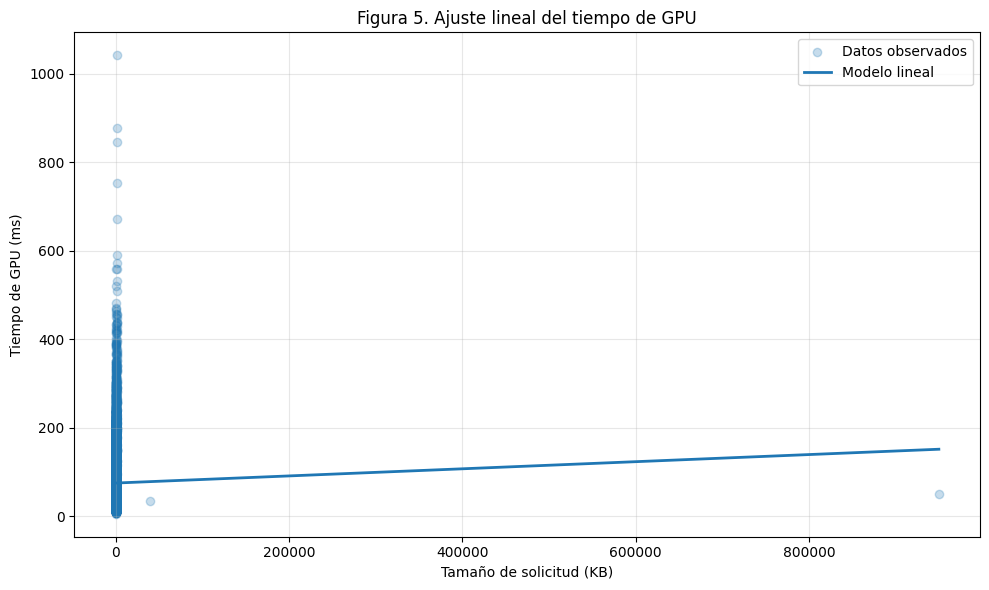

In [412]:
orden = np.argsort(X)
plt.figure(figsize=(10, 6))

plt.scatter(
    X,
    G,
    alpha=0.25,
    label="Datos observados"
)

plt.plot(
    X[orden],
    G_estimado[orden],
    linewidth=2,
    label="Modelo lineal"
)

plt.xlabel("Tamaño de solicitud (KB)")
plt.ylabel("Tiempo de GPU (ms)")
plt.title("Figura 5. Ajuste lineal del tiempo de GPU")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

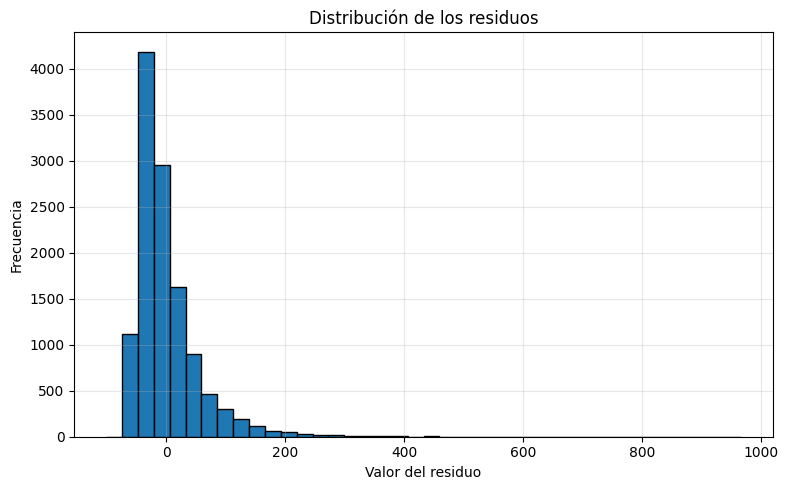

In [413]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuos,
    bins=40,
    edgecolor="black"
)

plt.xlabel("Valor del residuo")
plt.ylabel("Frecuencia")
plt.title("Distribución de los residuos")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [414]:
# Elevamos los residuos al cuadrado
residuos2 = residuos**2

# Construimos la matriz auxiliar
Z_aux = np.column_stack([
    np.ones(n),
    Z
])

# Calculamos los coeficientes de la regresión auxiliar
coef_aux = np.linalg.lstsq(
    Z_aux,
    residuos2,
    rcond=None
)[0]

# Calculamos los valores estimados auxiliares
residuos2_estimados = Z_aux @ coef_aux

# Calculamos la suma total de cuadrados
SST_aux = np.sum(
    (residuos2 - np.mean(residuos2))**2
)

# Calculamos la suma de errores al cuadrado
SSE_aux = np.sum(
    (residuos2 - residuos2_estimados)**2
)

# Calculamos el R cuadrado auxiliar
R2_aux = 1 - SSE_aux / SST_aux

# Calculamos el estadístico de Breusch-Pagan
LM = n * R2_aux

# Calculamos el valor p usando chi-cuadrado
p_valor_BP = chi2_dist.sf(LM, df=1)

print("R² auxiliar =", R2_aux)
print("Estadístico LM =", LM)
print("Valor p =", p_valor_BP)

# Interpretamos con significancia del 1%
if p_valor_BP < 0.01:
    print("\nExiste evidencia de heterocedasticidad.")
else:
    print("\nNo existe evidencia suficiente de heterocedasticidad.")

R² auxiliar = 0.00018370309648285676
Estadístico LM = 2.2191334055129097
Valor p = 0.1363095521828629

No existe evidencia suficiente de heterocedasticidad.


In [415]:
# Comprobamos si existe evidencia de heterocedasticidad
if p_valor_BP < 0.01:

    # Dividimos los tamaños de las solicitudes en 10 grupos
    grupos = pd.qcut(
        X,
        q=10,
        duplicates="drop"
    )

    # Creamos una tabla con los grupos y los residuos
    tabla = pd.DataFrame({
        "grupo": grupos,
        "residuo": residuos
    })

    # Calculamos la varianza de los residuos en cada grupo
    varianzas = tabla.groupby(
        "grupo",
        observed=True
    )["residuo"].var()

    # Asignamos a cada observación la varianza de su grupo
    varianza_estimada = tabla["grupo"].map(
        varianzas
    ).to_numpy(dtype=float)

    # Evitamos varianzas nulas o no válidas
    varianza_estimada = np.maximum(
        varianza_estimada,
        1e-12
    )

    # Calculamos los pesos inversos a la varianza
    pesos = 1 / varianza_estimada
    # Construimos el sistema matricial ponderado
    A_WLS = matriz_X.T @ (matriz_X * pesos[:, None])
    b_WLS = matriz_X.T @ (pesos * G)

    # Resolvemos el sistema matricial
    coef_WLS = np.linalg.solve(A_WLS, b_WLS)
    # Obtenemos el intercepto centrado
    alpha_WLS = coef_WLS[0]
    # Obtenemos la pendiente
    beta1_WLS = coef_WLS[1]
    # Recuperamos el intercepto original
    beta0_WLS = alpha_WLS - beta1_WLS * promedio_X
    # Calculamos las predicciones del modelo corregido
    G_WLS = beta0_WLS + beta1_WLS * X
    # Calculamos los residuos del modelo corregido
    residuos_WLS = G - G_WLS


    print("Intercepto:", beta0_WLS)
    print("Pendiente:", beta1_WLS)

    print("\nEcuación del modelo corregido:")
    print(f"G = {beta0_WLS:.6f} + ({beta1_WLS:.6f})X")

else:

    print("No se aplica WLS.")
    print("No se encontró evidencia suficiente de heterocedasticidad.")

No se aplica WLS.
No se encontró evidencia suficiente de heterocedasticidad.


In [416]:
# Comprobamos si se aplicó WLS
if p_valor_BP < 0.01:

    # Calculamos la suma ponderada de los errores al cuadrado
    SSE_WLS = np.sum(
        pesos * residuos_WLS**2
    )

    # Calculamos la varianza residual estimada
    s2_WLS = SSE_WLS / (n - 2)
    # Calculamos la matriz de covarianzas
    matriz_cov_WLS = s2_WLS * np.linalg.inv(A_WLS)
    # Calculamos el error estándar del intercepto centrado
    EE_alpha_WLS = np.sqrt(matriz_cov_WLS[0, 0])
    # Calculamos el error estándar de la pendiente
    EE_beta1_WLS = np.sqrt(matriz_cov_WLS[1, 1])
    # Calculamos el error estándar del intercepto original
    EE_beta0_WLS = np.sqrt(
        matriz_cov_WLS[0, 0] +
        promedio_X**2 * matriz_cov_WLS[1, 1]
    )

    # Calculamos el valor crítico t
    t_critico_WLS = t.ppf(0.995, n - 2)
    # Calculamos los intervalos del intercepto
    IC_beta0_WLS = (
        beta0_WLS - t_critico_WLS * EE_beta0_WLS,
        beta0_WLS + t_critico_WLS * EE_beta0_WLS
    )
    # Calculamos los intervalos de la pendiente
    IC_beta1_WLS = (
        beta1_WLS - t_critico_WLS * EE_beta1_WLS,
        beta1_WLS + t_critico_WLS * EE_beta1_WLS
    )

    print("Intercepto:")
    print("Error estándar:", EE_beta0_WLS)
    print("Intervalo:", IC_beta0_WLS)
    print("\nPendiente:")
    print("Error estándar:", EE_beta1_WLS)
    print("Intervalo:", IC_beta1_WLS)

else:

    print("Se conservan los intervalos del modelo OLS.")

Se conservan los intervalos del modelo OLS.


In [417]:
# Comprobamos si se aplicó WLS
if p_valor_BP < 0.01:

    # Ordenamos los datos según el tamaño
    orden = np.argsort(X)
    # Creamos la gráfica
    plt.figure(figsize=(10, 6))

    # Mostramos los datos observados
    plt.scatter(
        X,
        G,
        alpha=0.2,
        label="Datos observados"
    )
    # Dibujamos el modelo original
    plt.plot(
        X[orden],
        G_estimado[orden],
        linewidth=2,
        label="Modelo OLS"
    )

    # Dibujamos el modelo corregido
    plt.plot(
        X[orden],
        G_WLS[orden],
        linewidth=2,
        label="Modelo WLS"
    )


    plt.xlabel("Tamaño de solicitud (KB)")
    plt.ylabel("Tiempo de GPU (ms)")
    plt.title("Comparación entre OLS y WLS")
    plt.legend()


    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:

    print("No se realizó la comparación porque no se aplicó WLS.")

No se realizó la comparación porque no se aplicó WLS.


In [418]:
if p_valor_BP < 0.01:

    plt.figure(figsize=(10, 6))
    plt.scatter(
        X,
        residuos_WLS,
        alpha=0.3
    )
    plt.axhline(
        y=0,
        linestyle="--"
    )


    plt.xlabel("Tamaño de solicitud (KB)")
    plt.ylabel("Residuos WLS")
    plt.title("Residuos del modelo corregido WLS")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

else:

    print("El análisis de residuos corresponde al modelo OLS.")

El análisis de residuos corresponde al modelo OLS.


D4

In [420]:
# Obtenemos el tamaño de las solicitudes
X_D4 = datos_D3["tam_kb"].to_numpy(dtype=float)
# Obtenemos el tiempo de procesamiento de la GPU
G_D4 = datos_D3["gpu_ms"].to_numpy(dtype=float)
# Calculamos la cantidad de observaciones
n_D4 = len(X_D4)

# Calculamos los promedios
promedio_X_D4 = np.mean(X_D4)
promedio_G_D4 = np.mean(G_D4)

print("Cantidad de observaciones:", n_D4)
print("Promedio de tamaño:", promedio_X_D4)
print("Promedio de GPU:", promedio_G_D4)

Cantidad de observaciones: 12080
Promedio de tamaño: 306.3852127483444
Promedio de GPU: 75.19469619205297


In [421]:
# Calculamos las diferencias respecto a los promedios
dif_X = X_D4 - promedio_X_D4
dif_G = G_D4 - promedio_G_D4

# Multiplicamos las diferencias
productos = dif_X * dif_G
# Sumamos los productos
suma_productos = np.sum(productos)
# Calculamos la covarianza muestral
covarianza = suma_productos / (n_D4 - 1)

print("Sumatoria de productos:", suma_productos)
print("Covarianza:", covarianza)

Sumatoria de productos: 72694672.61818078
Covarianza: 6018.269113186587


In [422]:
# Calculamos las desviaciones estándar muestrales
desviacion_X = np.std(X_D4, ddof=1)
desviacion_G = np.std(G_D4, ddof=1)
correlacion = covarianza / (desviacion_X * desviacion_G)


print("Desviación estándar X:", desviacion_X)
print("Desviación estándar G:", desviacion_G)
print("Correlación:", correlacion)

Desviación estándar X: 8651.020583791807
Desviación estándar G: 57.39913546508203
Correlación: 0.012119896391593006


In [423]:
# Calculamos la covarianza con NumPy
covarianza_verificacion = np.cov(
    X_D4,
    G_D4,
    ddof=1
)[0, 1]

# Calculamos la correlación con NumPy
correlacion_verificacion = np.corrcoef(
    X_D4,
    G_D4
)[0, 1]

print("Covarianza calculada:", covarianza)
print("Covarianza NumPy:", covarianza_verificacion)
print("\nCorrelación calculada:", correlacion)
print("Correlación NumPy:", correlacion_verificacion)

Covarianza calculada: 6018.269113186587
Covarianza NumPy: 6018.2691131865895

Correlación calculada: 0.012119896391593006
Correlación NumPy: 0.012119896391593011


In [425]:
# Ordenamos los registros por tamaño de solicitud
extremos_D4 = datos_D3.sort_values(
    by="tam_kb",
    ascending=False
)

# Mostramos los 10 tamaños más grandes
display(
    extremos_D4[
        ["tam_kb", "gpu_ms", "cache_hit"]
    ].head(10)
)

# Mostramos los principales estadísticos
print("ESTADÍSTICOS DE D4")
print(datos_D3[["tam_kb", "gpu_ms"]].describe())

,tam_kb,gpu_ms,cache_hit
8501,"950,000.000000",50.340000,0
16989,"40,000.000000",35.720000,0
4464,"2,175.890000",846.580000,0
7017,"2,137.320000",366.060000,0
4510,"2,112.720000",195.300000,0
14185,"1,944.780000",876.670000,0
7527,"1,940.390000",437.470000,0
12612,"1,821.980000","1,041.630000",0
7158,"1,766.450000",456.220000,0
17861,"1,723.120000",591.420000,0


ESTADÍSTICOS DE D4
              tam_kb        gpu_ms
count  12,080.000000 12,080.000000
mean      306.385213     75.194696
std     8,651.020584     57.399135
min         7.510000      5.700000
25%       110.220000     39.690000
50%       169.400000     59.555000
75%       275.780000     91.712500
max   950,000.000000  1,041.630000


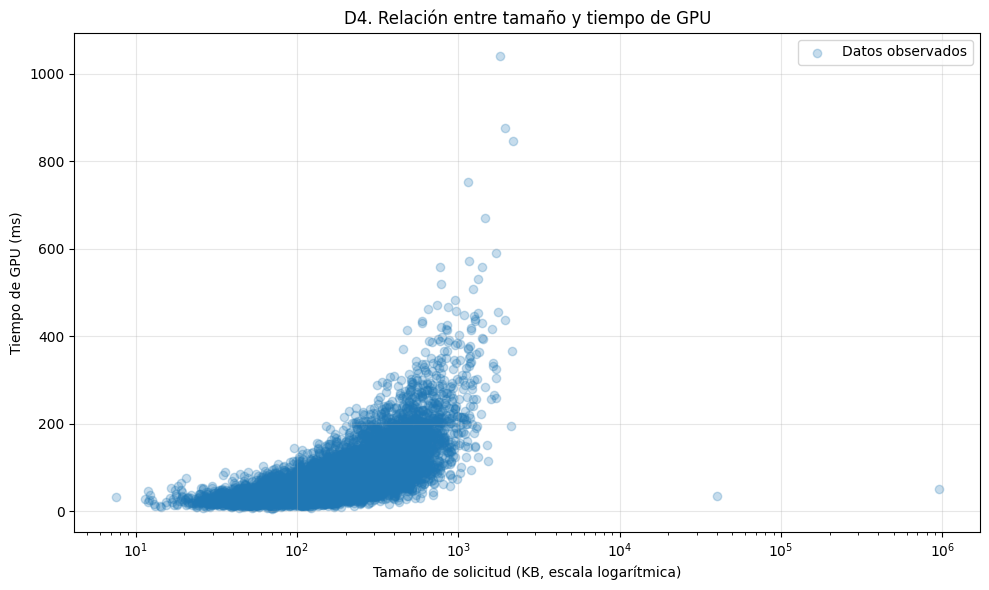

In [426]:
# Creamos la gráfica
plt.figure(figsize=(10, 6))

# Dibujamos los datos observados
plt.scatter(
    X_D4,
    G_D4,
    alpha=0.25,
    label="Datos observados"
)

plt.xscale("log")
plt.xlabel("Tamaño de solicitud (KB, escala logarítmica)")
plt.ylabel("Tiempo de GPU (ms)")
plt.title("D4. Relación entre tamaño y tiempo de GPU")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [429]:
# Interpretamos la dirección de la correlación
if correlacion > 0:
    print("La relación entre las variables es positiva.")
elif correlacion < 0:
    print("La relación entre las variables es negativa.")
else:
    print("No existe una relación lineal.")

# Interpretamos la intensidad
valor = abs(correlacion)

if valor < 0.30:
    print("La relación lineal es débil.")
elif valor < 0.70:
    print("La relación lineal es moderada.")
else:
    print("La relación lineal es fuerte.")

print("\nCorrelación obtenida:", correlacion)

La relación entre las variables es positiva.
La relación lineal es débil.

Correlación obtenida: 0.012119896391593006
